# Combined results figure

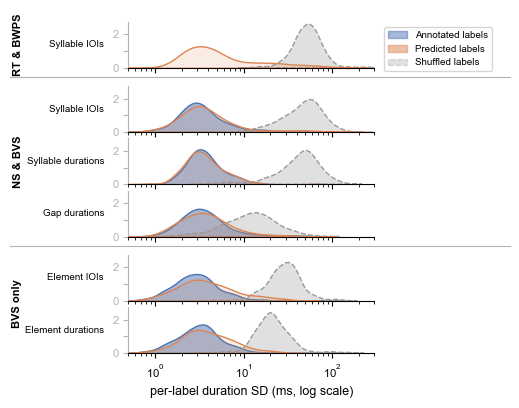

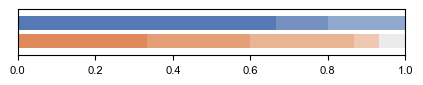

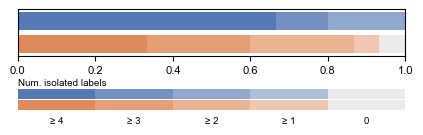

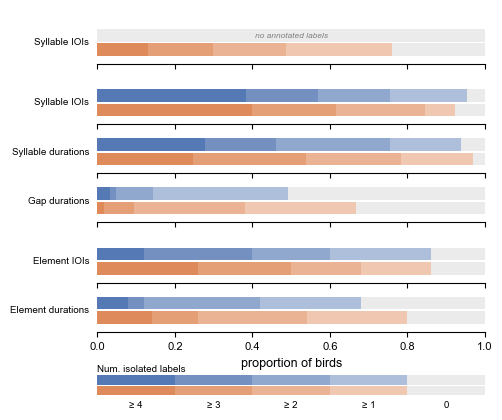

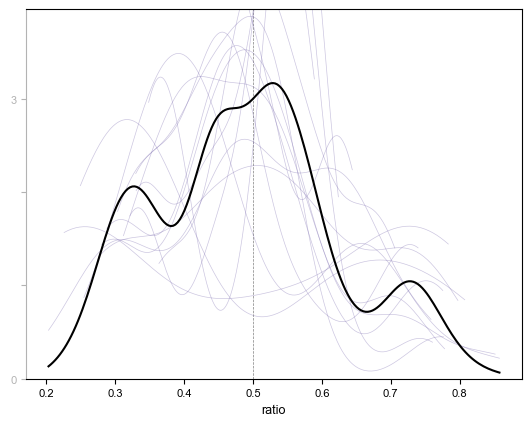

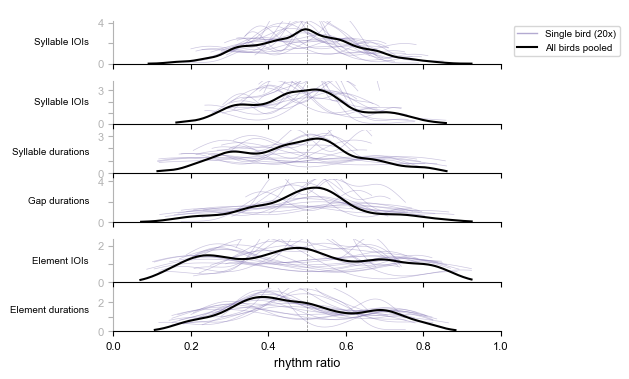

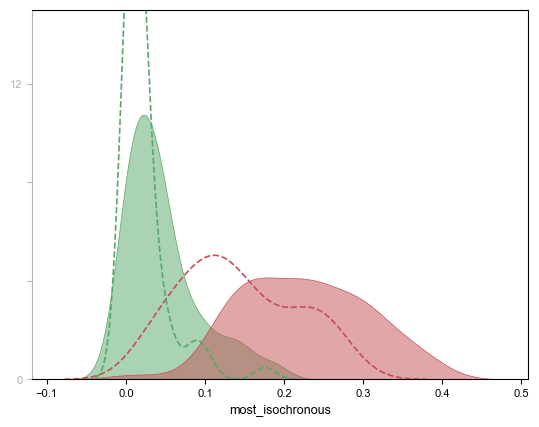

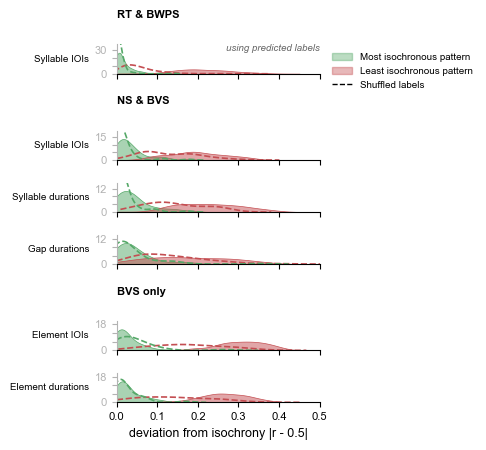

In [1]:
# Run notebooks with individual subfigures
%run fig2a-consistency.ipynb
%run fig2b-differentiation.ipynb
%run fig2c-ratio-plots.ipynb
%run fig2d-isochrony-scores.ipynb

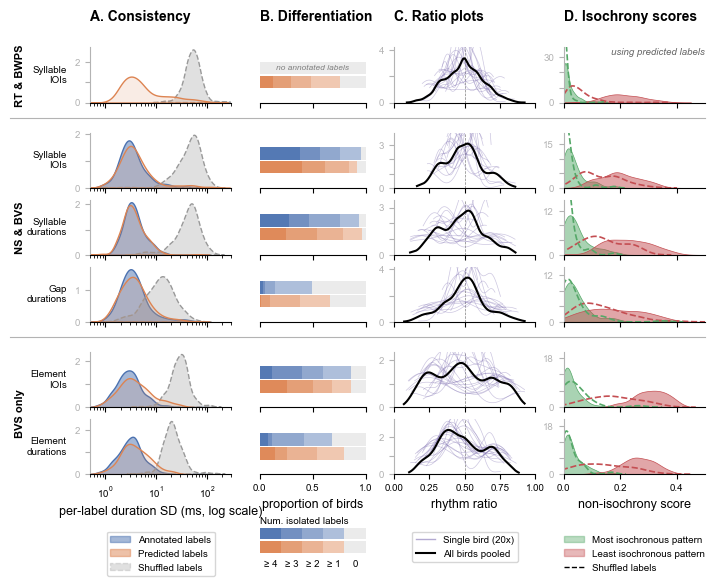

In [2]:
from viz.rows import row_height_ratios, annotate_row_groups
from fig2_settings import SECTIONS, build_row_specs

row_specs = build_row_specs(SECTIONS, wrap=True)
ROW_HEIGHT_RATIOS = row_height_ratios(row_specs, header_ratio=0.12)

# All sizes in inches; target total width is 174 mm (6.85 in)
COL_WIDTH = 1.4
COL_WIDTH_RATIOS = [1, 0.75, 1, 1]
LEFT_MARGIN, RIGHT_MARGIN = .8, 0
TOP_MARGIN, BOTTOM_MARGIN = 0.35, 2.1
WSPACE_IN = 0.3
ROW_HEIGHT = 0.7

LEGEND_KWS = dict(legend_loc='upper center', legend_bbox_to_anchor=(0.5, -0.95), legend_ax='last')
N_ROWS = len(row_specs)
fig_width = LEFT_MARGIN + sum(COL_WIDTH_RATIOS) * COL_WIDTH + 3 * WSPACE_IN + RIGHT_MARGIN
fig_height = ROW_HEIGHT * sum(ROW_HEIGHT_RATIOS) + TOP_MARGIN + BOTTOM_MARGIN

fig, axes = plt.subplots(
    N_ROWS, 4, figsize=(fig_width, fig_height), sharex='col',
    gridspec_kw=dict(
        height_ratios=ROW_HEIGHT_RATIOS,
        width_ratios=COL_WIDTH_RATIOS,
        left=LEFT_MARGIN / fig_width, right=1 - RIGHT_MARGIN / fig_width,
        top=1 - TOP_MARGIN / fig_height, bottom=BOTTOM_MARGIN / fig_height,
        wspace=WSPACE_IN / COL_WIDTH, 
        hspace=0.3,
    ),
)

plot_consistency_column(axes[:, 0], row_specs, label_metrics, show_row_labels=True, legend=True, **LEGEND_KWS)
plot_differentiation_column(axes[:, 1], row_specs, bird_metrics, bar_pad=1, show_row_labels=False, legend=True, **LEGEND_KWS)
plot_ratio_column(axes[:, 2], row_specs, show_row_labels=False, legend=True, **LEGEND_KWS)
plot_isochrony_column(axes[:, 3], row_specs, bird_summary, show_row_labels=False, legend=True, **LEGEND_KWS)

axes[-1, 0].set_xlim(0.5, 300)
axes[-1, 0].set_xlabel('per-label duration SD (ms, log scale)')
axes[-1, 1].set_xlabel('proportion of birds')
axes[-1, 2].set_xlim(0, 1)
axes[-1, 2].set_xlabel('rhythm ratio')
axes[-1, 3].set_xlim(*SCORE_RANGE)
axes[-1, 3].set_xlabel('non-isochrony score')

titles = ['A. Consistency', 'B. Differentiation', 'C. Ratio plots', 'D. Isochrony scores']
for col, title in enumerate(titles):
    axes[0, col].set_title(title, loc='left', fontsize=10, fontweight='bold')


for ax in fig.axes:
    ax.tick_params(labelsize=7)
    ax.xaxis.label.set_fontsize(9)

for col in range(axes.shape[1]):
    for ax in axes[:, col]:
        sns.despine(ax=ax, left=(col == 1))

annotate_row_groups(fig, axes[:, 0], row_specs)
from viz.utils import savefig
savefig('fig2-results', bbox_inches='tight', pad_inches=0.02)